# Calories Burnt Prediction
Multivariate Linear Regression using Gradient Descent and OLS

## 1. Data Preprocessing
### Load and inspect the datasets

In [1]:
from google.colab import files
uploaded = files.upload()

Saving exercise.csv to exercise.csv
Saving calories.csv to calories.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

exercise = pd.read_csv("exercise.csv")
calories = pd.read_csv("calories.csv")

print("Exercise dataset shape:", exercise.shape)
print("Calories dataset shape:", calories.shape)

display(exercise.head())
display(calories.head())

Exercise dataset shape: (15000, 8)
Calories dataset shape: (15000, 2)


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8


,User_ID,Calories
0,14733363,231.0
1,14861698,66.0
2,11179863,26.0
3,16180408,71.0
4,17771927,35.0


### Merge the datasets
The two datasets are merged using User_ID to match each exercise record with its Calories value.

In [6]:
data = pd.merge(exercise, calories, on="User_ID", validate="one_to_one")

print("Merged dataset shape:", data.shape)
print("All exercise records matched:", len(data) == len(exercise))

display(data.head())

Merged dataset shape: (15000, 9)
All exercise records matched: True


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


## 2. Data Cleaning
### Check data types, missing values, and duplicates

In [7]:
print("Data types:")
print(data.dtypes)

print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())
print("Duplicate User_ID values:", data["User_ID"].duplicated().sum())

print("\nGender values:")
print(data["Gender"].value_counts(dropna=False))

Data types:
User_ID         int64
Gender         object
Age             int64
Height        float64
Weight        float64
Duration      float64
Heart_Rate    float64
Body_Temp     float64
Calories      float64
dtype: object

Missing values:
User_ID       0
Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64

Duplicate rows: 0
Duplicate User_ID values: 0

Gender values:
Gender
female    7553
male      7447
Name: count, dtype: int64


The dataset contains no missing values, duplicate rows, or repeated User_ID values. Numerical columns have appropriate data types. Gender contains two categories: female (7,553) and male (7,447). No missing-value filling or duplicate removal was needed.

### Check outliers
Boxplots and the IQR method are used to identify unusual numerical values. User_ID is excluded because it is an identifier.

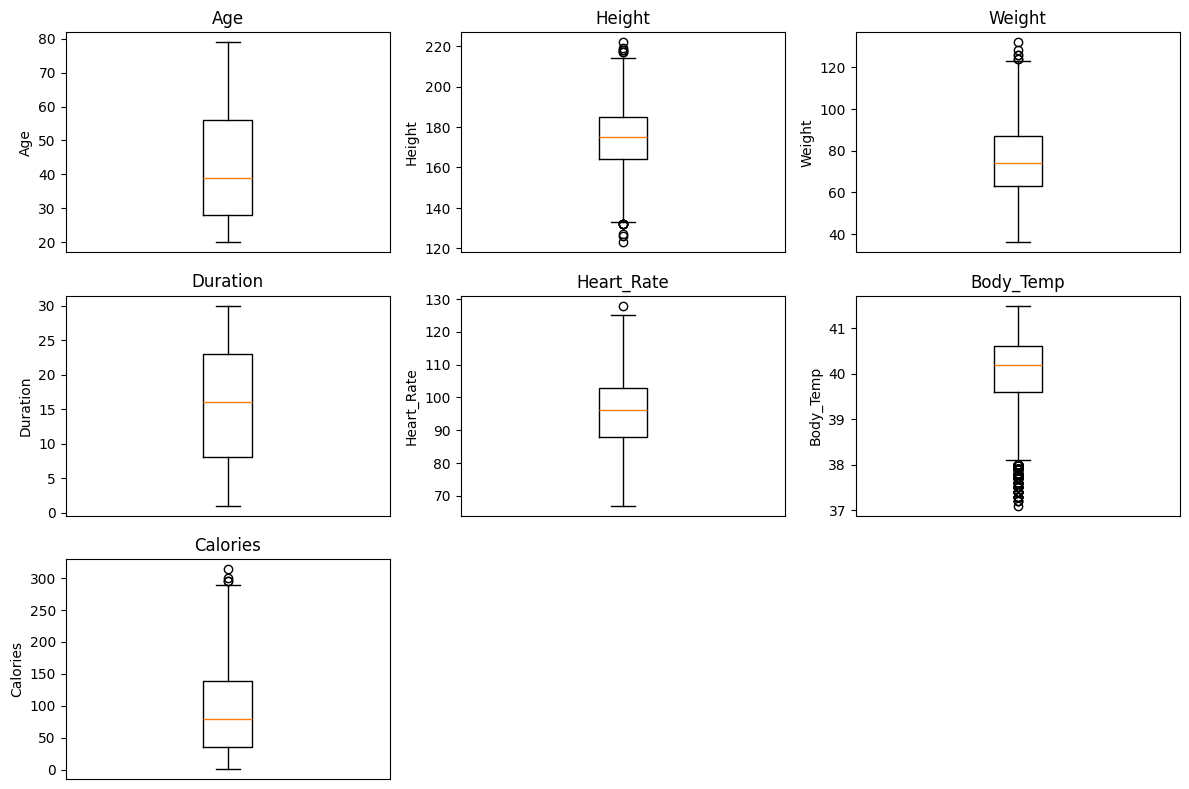

In [8]:
numeric_columns = [
    "Age", "Height", "Weight", "Duration",
    "Heart_Rate", "Body_Temp", "Calories"
]

plt.figure(figsize=(12, 8))

for i, column in enumerate(numeric_columns):
    plt.subplot(3, 3, i + 1)
    plt.boxplot(data[column])
    plt.title(column)
    plt.ylabel(column)
    plt.xticks([])

plt.tight_layout()
plt.show()

In [9]:
Q1 = data[numeric_columns].quantile(0.25)
Q3 = data[numeric_columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (
    (data[numeric_columns] < lower_bound) |
    (data[numeric_columns] > upper_bound)
)

print("Outlier counts:")
print(outliers.sum())

display(data[numeric_columns].describe().loc[["min", "max"]])

Outlier counts:
Age             0
Height         14
Weight          6
Duration        0
Heart_Rate      1
Body_Temp     369
Calories        4
dtype: int64


,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
min,20.0,123.0,36.0,1.0,67.0,37.1,1.0
max,79.0,222.0,132.0,30.0,128.0,41.5,314.0


The IQR method flagged 14 Height values, 6 Weight values, 1 Heart_Rate value, 369 Body_Temp values, and 4 Calories values. Age and Duration had no flagged values.

These records were retained because an IQR flag alone does not establish a measurement error. The Body_Temp range of 37.1–41.5°C requires caution because measurement details are unavailable. No rows were removed or capped.

## 3. Data Preprocessing — Encoding and Train/Test Split
Gender is encoded as female = 0 and male = 1. User_ID is removed because it is an identifier. An 80/20 split is used for training and testing.

In [10]:
model_data = data.copy()

model_data["Gender"] = model_data["Gender"].map({
    "female": 0,
    "male": 1
})

model_data = model_data.drop(columns=["User_ID"])

train_data = model_data.sample(frac=0.8, random_state=42)
test_data = model_data.drop(index=train_data.index)

train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print("Training data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

print("\nEncoded Gender values:")
print(model_data["Gender"].value_counts())

Training data shape: (12000, 8)
Test data shape: (3000, 8)

Encoded Gender values:
Gender
0    7553
1    7447
Name: count, dtype: int64


## 4. Linear Regression Assumption — Linearity
Scatterplots are used to examine the relationship between each predictor and Calories in the training data. Gender is binary, so its plot shows two groups rather than a continuous trend.

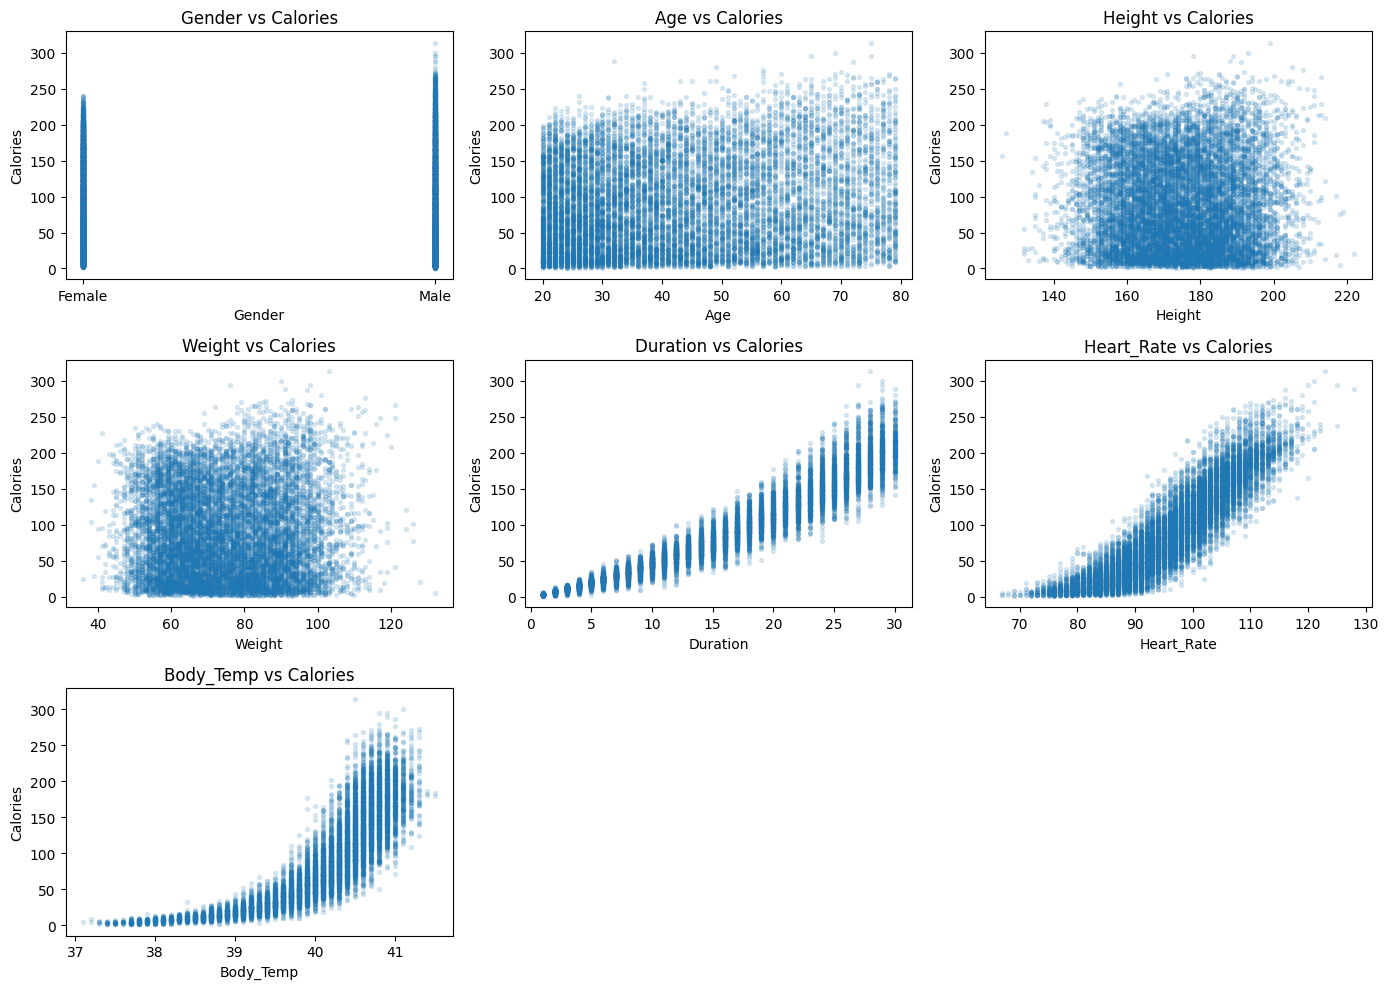

In [11]:
predictors = [
    "Gender", "Age", "Height", "Weight",
    "Duration", "Heart_Rate", "Body_Temp"
]

plt.figure(figsize=(14, 10))

for i, column in enumerate(predictors):
    plt.subplot(3, 3, i + 1)
    plt.scatter(
        train_data[column],
        train_data["Calories"],
        alpha=0.15,
        s=8
    )
    plt.xlabel(column)
    plt.ylabel("Calories")
    plt.title(f"{column} vs Calories")

    if column == "Gender":
        plt.xticks([0, 1], ["Female", "Male"])

plt.tight_layout()
plt.show()

Calories generally increase with Duration, Heart_Rate, and Body_Temp, but these relationships show curvature, especially for Body_Temp. Age, Height, and Weight show weaker individual patterns with considerable scatter. Gender forms two groups because it is binary.

The plots do not fully support straight-line relationships for all predictors. A model using only raw linear terms may miss curved patterns and produce systematic prediction errors. Engineered features may help capture some of these patterns. These plots are an initial check rather than a complete assessment of the multivariate relationship.

## 5. Feature Engineering
Three features are added alongside the original predictors:

- BMI = Weight / (Height in meters)²: represents weight relative to height.
- Duration_Heart_Rate = Duration × Heart_Rate: allows the effect of exercise duration to vary with heart rate.
- Duration_Squared = Duration²: allows a curved relationship between exercise duration and Calories.

Their usefulness will be evaluated by comparing raw-only and engineered-feature models.

In [12]:
for dataset in [train_data, test_data]:
    dataset["BMI"] = dataset["Weight"] / (dataset["Height"] / 100) ** 2
    dataset["Duration_Heart_Rate"] = dataset["Duration"] * dataset["Heart_Rate"]
    dataset["Duration_Squared"] = dataset["Duration"] ** 2

print("Training data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

display(train_data[
    ["BMI", "Duration_Heart_Rate", "Duration_Squared"]
].head())

Training data shape: (12000, 11)
Test data shape: (3000, 11)


,BMI,Duration_Heart_Rate,Duration_Squared
0,21.926126,2782.0,676.0
1,25.737081,3219.0,841.0
2,24.857955,990.0,121.0
3,26.868736,2592.0,576.0
4,22.913033,3364.0,841.0


## 6. Model Training & Development
### Prepare and scale the features
Calories is separated as the target. Predictors are standardized using the training means and standard deviations. The same training statistics are used to scale the test data to avoid data leakage. A column of ones is added for the intercept.

In [13]:
feature_names = train_data.drop(columns=["Calories"]).columns.tolist()

X_train = train_data[feature_names].to_numpy(dtype=float)
X_test = test_data[feature_names].to_numpy(dtype=float)

y_train = train_data["Calories"].to_numpy(dtype=float)
y_test = test_data["Calories"].to_numpy(dtype=float)

train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)

X_train_scaled = (X_train - train_mean) / train_std
X_test_scaled = (X_test - train_mean) / train_std

X_train_bias = np.column_stack((np.ones(len(X_train)), X_train_scaled))
X_test_bias = np.column_stack((np.ones(len(X_test)), X_test_scaled))

print("Training input shape:", X_train_bias.shape)
print("Test input shape:", X_test_bias.shape)
print("Training target shape:", y_train.shape)
print("Test target shape:", y_test.shape)

print("\nScaled training means:")
print(X_train_scaled.mean(axis=0).round(6))

print("\nScaled training standard deviations:")
print(X_train_scaled.std(axis=0).round(6))

Training input shape: (12000, 11)
Test input shape: (3000, 11)
Training target shape: (12000,)
Test target shape: (3000,)

Scaled training means:
[-0. -0.  0.  0. -0.  0. -0.  0. -0. -0.]

Scaled training standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Task 1 — Gradient Descent from Scratch
Weights, including the intercept, are initialized to zero. The cost is Mean Squared Error (MSE). Each iteration updates the weights in the direction that reduces this cost.

Prediction: y_pred = X @ weights

MSE = mean((y_pred - y)²)

Gradient = (2 / m) × X.T @ (y_pred - y)

Update: weights = weights - learning_rate × gradient

In [15]:
def compute_cost(X, y, weights):
    errors = X @ weights - y
    return np.mean(errors ** 2)


def gradient_descent(X, y, learning_rate, iterations):
    weights = np.zeros(X.shape[1])
    cost_history = []
    m = len(y)

    for iteration in range(iterations):
        cost = compute_cost(X, y, weights)

        if not np.isfinite(cost) or cost > 1e20:
            break

        cost_history.append(cost)

        predictions = X @ weights
        errors = predictions - y
        gradient = (2 / m) * (X.T @ errors)

        weights = weights - learning_rate * gradient

    return weights, cost_history

### Learning Rate Experiment
Learning rates of 0.001, 0.01, 0.1, 0.5, and 1.0 are tested. Each run starts with zero weights and allows 10,000 updates. Runs with excessively large or non-finite costs are stopped by the numerical safeguard.

In [16]:
import time

learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
iterations = 10000

gd_results = {}
summary = []

for rate in learning_rates:
    start = time.perf_counter()

    weights, costs = gradient_descent(
        X_train_bias, y_train, rate, iterations
    )

    training_time = time.perf_counter() - start
    final_cost = compute_cost(X_train_bias, y_train, weights)

    stopped = (
        len(costs) < iterations
        or not np.isfinite(final_cost)
        or final_cost > 1e20
    )

    gd_results[rate] = {
        "weights": weights,
        "costs": costs,
        "training_time": training_time,
        "final_cost": final_cost,
        "diverged": stopped
    }

    summary.append({
        "Learning rate": rate,
        "Updates": len(costs),
        "Final training MSE": final_cost,
        "Time (seconds)": training_time,
        "Status": "Diverged" if stopped else "Completed"
    })

display(pd.DataFrame(summary))

,Learning rate,Updates,Final training MSE,Time (seconds),Status
0,0.001,10000,8.941637e+01,2.496217,Completed
1,0.010,10000,7.587047e+01,1.807375,Completed
2,0.100,10000,6.017738e+01,1.762258,Completed
3,0.500,15,1.264285e+20,0.002721,Diverged
4,1.000,10,5.638661e+21,0.001775,Diverged


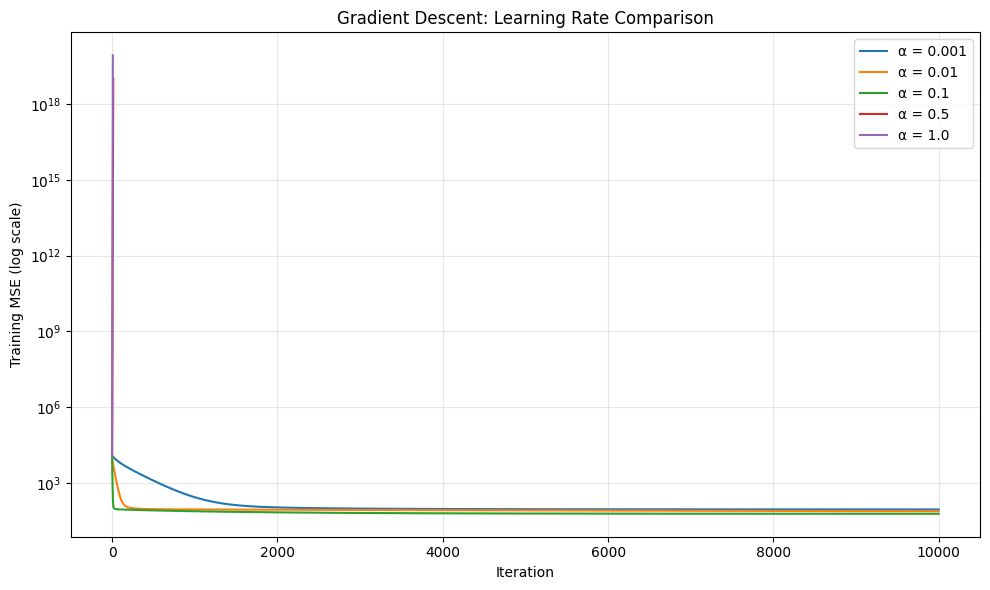

In [17]:
plt.figure(figsize=(10, 6))

for rate in learning_rates:
    costs = gd_results[rate]["costs"]
    plt.plot(range(len(costs)), costs, label=f"α = {rate}")

plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Training MSE (log scale)")
plt.title("Gradient Descent: Learning Rate Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The learning rates 0.001, 0.01, and 0.1 reduced the training cost. At 10,000 updates, 0.1 achieved the lowest training MSE (60.18), compared with 75.87 for 0.01 and 89.42 for 0.001.

Rates of 0.5 and 1.0 caused rapidly increasing costs and triggered the numerical safeguard. No clear oscillation in cost is visible for the stable runs at this plot scale.

A learning rate of 0.1 was selected based on training cost, without using test results. Completing 10,000 updates does not by itself establish full convergence.

### Evaluation & Results — Gradient Descent
The stable GD models are evaluated on the same test set using MAE, RMSE, and R². Diverged runs are excluded from meaningful predictive evaluation.

In [18]:
def evaluate_model(y_actual, y_predicted):
    errors = y_actual - y_predicted

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    ss_res = np.sum(errors ** 2)
    ss_total = np.sum((y_actual - y_actual.mean()) ** 2)
    r2 = 1 - ss_res / ss_total

    return mae, rmse, r2


stable_rates = [
    rate for rate in learning_rates
    if not gd_results[rate]["diverged"]
]

best_rate = min(
    stable_rates,
    key=lambda rate: gd_results[rate]["final_cost"]
)

gd_weights = gd_results[best_rate]["weights"]
gd_time = gd_results[best_rate]["training_time"]

gd_metrics = []

for rate in stable_rates:
    predictions = X_test_bias @ gd_results[rate]["weights"]
    mae, rmse, r2 = evaluate_model(y_test, predictions)

    gd_metrics.append({
        "Learning rate": rate,
        "Test MAE": mae,
        "Test RMSE": rmse,
        "Test R²": r2
    })

print("Selected learning rate:", best_rate)
display(pd.DataFrame(gd_metrics))

gd_predictions = X_test_bias @ gd_weights
gd_mae, gd_rmse, gd_r2 = evaluate_model(y_test, gd_predictions)

gd_coefficients = pd.DataFrame({
    "Term": ["Intercept"] + feature_names,
    "Coefficient (scaled inputs)": gd_weights
})

display(gd_coefficients)

Selected learning rate: 0.1


,Learning rate,Test MAE,Test RMSE,Test R²
0,0.001,6.872707,9.454369,0.977172
1,0.010,6.309996,8.731663,0.980528
2,0.100,5.836811,7.898100,0.984069


,Term,Coefficient (scaled inputs)
0,Intercept,89.647000
1,Gender,-0.074293
2,Age,8.625105
3,Height,-29.429273
4,Weight,37.754166
5,Duration,-56.452535
6,Heart_Rate,0.777854
7,Body_Temp,0.070428
8,BMI,-11.417478
9,Duration_Heart_Rate,114.305439


### Task 2 — Ordinary Least Squares (OLS)

OLS finds coefficients that minimize the sum of squared prediction errors.

Starting with:
SSE = (y - Xβ)ᵀ(y - Xβ)

Setting its gradient to zero gives:
XᵀXβ = Xᵀy

Therefore, when XᵀX is invertible:
β = (XᵀX)⁻¹Xᵀy

NumPy's solve function is used to solve the normal equations without explicitly calculating the inverse. The same standardized inputs are used for GD and OLS.

In [19]:
start = time.perf_counter()

ols_weights = np.linalg.solve(
    X_train_bias.T @ X_train_bias,
    X_train_bias.T @ y_train
)

ols_time = time.perf_counter() - start

ols_predictions = X_test_bias @ ols_weights

ols_mae, ols_rmse, ols_r2 = evaluate_model(
    y_test, ols_predictions
)

display(pd.DataFrame([{
    "Model": "OLS",
    "Test MAE": ols_mae,
    "Test RMSE": ols_rmse,
    "Test R²": ols_r2,
    "Training time (seconds)": ols_time
}]))

ols_raw_weights = ols_weights[1:] / train_std
ols_raw_intercept = ols_weights[0] - train_mean @ ols_raw_weights

ols_coefficients = pd.DataFrame({
    "Term": ["Intercept"] + feature_names,
    "Coefficient (scaled inputs)": ols_weights,
    "Coefficient (original units)": np.concatenate(
        ([ols_raw_intercept], ols_raw_weights)
    )
})

display(ols_coefficients)

,Model,Test MAE,Test RMSE,Test R²,Training time (seconds)
0,OLS,5.84907,7.899607,0.984063,0.00178


,Term,Coefficient (scaled inputs),Coefficient (original units)
0,Intercept,89.647000,323.949113
1,Gender,-0.077156,-0.154314
2,Age,8.624991,0.507878
3,Height,-29.541822,-2.077946
4,Weight,37.895718,2.529605
5,Duration,-60.806059,-7.321125
6,Heart_Rate,-0.323546,-0.033685
7,Body_Temp,0.188816,0.243908
8,BMI,-11.458341,-7.351157
9,Duration_Heart_Rate,121.224487,0.130761


#### OLS coefficient interpretation

Using the coefficients in original units:

- Age: One additional year is associated with approximately 0.508 more predicted calories, holding the other predictors constant.
- Gender: With female = 0 and male = 1, the model predicts approximately 0.154 fewer calories for males than females with the other predictors held constant.
- Body_Temp: A 1°C increase is associated with approximately 0.244 more predicted calories, holding the other predictors constant.

These are model associations, not causal effects. Duration and Heart_Rate also appear in engineered terms, so their individual coefficients cannot be interpreted as their complete effects.

## 7. Task 3 — Comparison
### 7.1 Gradient Descent vs. OLS
Both models use the same features, training data, scaling, and test data.

In [20]:
comparison = pd.DataFrame({
    "Model": ["GD", "OLS"],
    "Training MSE": [
        compute_cost(X_train_bias, y_train, gd_weights),
        compute_cost(X_train_bias, y_train, ols_weights)
    ],
    "Test MAE": [gd_mae, ols_mae],
    "Test RMSE": [gd_rmse, ols_rmse],
    "Test R²": [gd_r2, ols_r2],
    "Training time (seconds)": [gd_time, ols_time]
})

display(comparison)

coefficient_comparison = pd.DataFrame({
    "Term": ["Intercept"] + feature_names,
    "GD (scaled inputs)": gd_weights,
    "OLS (scaled inputs)": ols_weights
})

display(coefficient_comparison)

,Model,Training MSE,Test MAE,Test RMSE,Test R²,Training time (seconds)
0,GD,60.177383,5.836811,7.898100,0.984069,1.762258
1,OLS,60.079736,5.849070,7.899607,0.984063,0.001780


,Term,GD (scaled inputs),OLS (scaled inputs)
0,Intercept,89.647000,89.647000
1,Gender,-0.074293,-0.077156
2,Age,8.625105,8.624991
3,Height,-29.429273,-29.541822
4,Weight,37.754166,37.895718
5,Duration,-56.452535,-60.806059
6,Heart_Rate,0.777854,-0.323546
7,Body_Temp,0.070428,0.188816
8,BMI,-11.417478,-11.458341
9,Duration_Heart_Rate,114.305439,121.224487


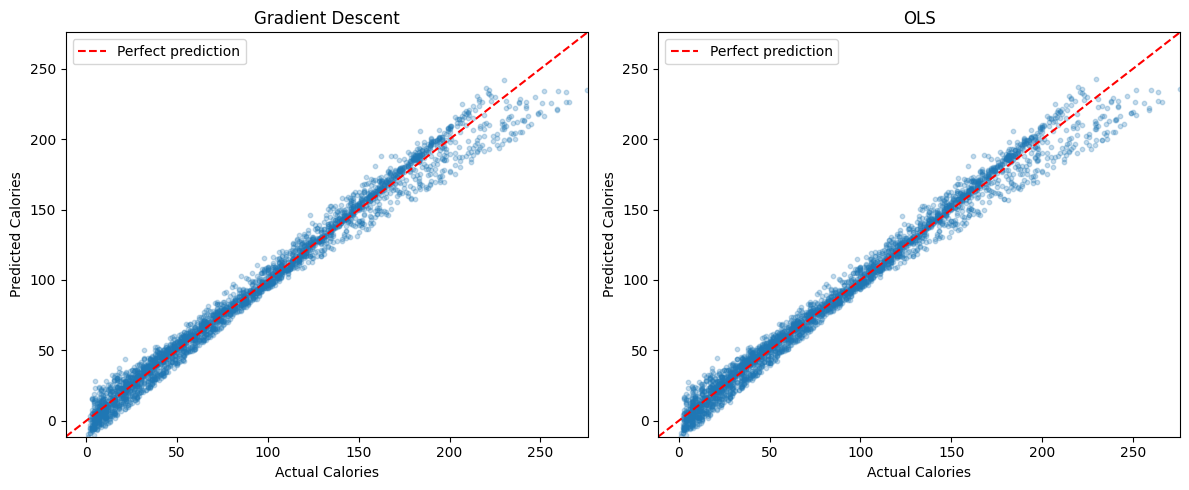

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

lower = min(y_test.min(), gd_predictions.min(), ols_predictions.min())
upper = max(y_test.max(), gd_predictions.max(), ols_predictions.max())

for ax, predictions, name in zip(
    axes,
    [gd_predictions, ols_predictions],
    ["Gradient Descent", "OLS"]
):
    ax.scatter(y_test, predictions, alpha=0.25, s=10)
    ax.plot([lower, upper], [lower, upper], "r--",
            label="Perfect prediction")
    ax.set_xlabel("Actual Calories")
    ax.set_ylabel("Predicted Calories")
    ax.set_title(name)
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.legend()

plt.tight_layout()
plt.show()

GD and OLS achieved almost identical test performance, with R² approximately 0.9841. GD had slightly lower test errors, while OLS achieved lower training MSE (60.0797 versus 60.1774).

The intercept and several coefficients were similar, but differences remained in Duration, Heart_Rate, and the engineered duration terms. GD had not fully reached the OLS solution after 10,000 updates. Correlated predictors can also allow similar predictions despite differences in individual coefficients.

OLS was more practical for this dataset because it achieved comparable test accuracy with much shorter measured training time (0.0018 seconds versus 1.7623 seconds). These timings depend on the runtime environment. Both models underpredicted some high-calorie observations.

OLS is selected for the raw-versus-engineered feature comparison based on its speed and comparable predictive performance.

### 7.2 Raw Features vs. Engineered Features
Model A uses the seven original predictors. Model B adds BMI, Duration_Heart_Rate, and Duration_Squared. Both models use OLS with the same training and test records.

In [22]:
raw_features = [
    "Gender", "Age", "Height", "Weight",
    "Duration", "Heart_Rate", "Body_Temp"
]

raw_indices = [feature_names.index(name) for name in raw_features]

X_train_raw = np.column_stack((
    np.ones(len(y_train)),
    X_train_scaled[:, raw_indices]
))

X_test_raw = np.column_stack((
    np.ones(len(y_test)),
    X_test_scaled[:, raw_indices]
))

raw_weights = np.linalg.solve(
    X_train_raw.T @ X_train_raw,
    X_train_raw.T @ y_train
)

raw_predictions = X_test_raw @ raw_weights

raw_mae, raw_rmse, raw_r2 = evaluate_model(
    y_test, raw_predictions
)

feature_comparison = pd.DataFrame({
    "Model": ["A: Raw features", "B: Raw + engineered features"],
    "Number of predictors": [7, 10],
    "Test MAE": [raw_mae, ols_mae],
    "Test RMSE": [raw_rmse, ols_rmse],
    "Test R²": [raw_r2, ols_r2]
})

display(feature_comparison)

,Model,Number of predictors,Test MAE,Test RMSE,Test R²
0,A: Raw features,7,8.408541,11.313070,0.967313
1,B: Raw + engineered features,10,5.849070,7.899607,0.984063


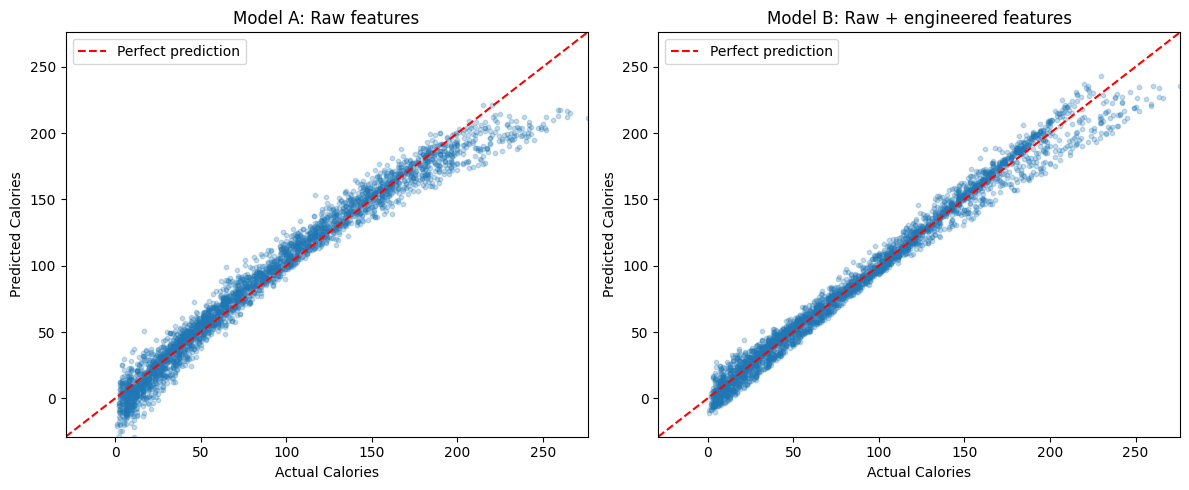

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

lower = min(y_test.min(), raw_predictions.min(), ols_predictions.min())
upper = max(y_test.max(), raw_predictions.max(), ols_predictions.max())

for ax, predictions, name in zip(
    axes,
    [raw_predictions, ols_predictions],
    ["Model A: Raw features", "Model B: Raw + engineered features"]
):
    ax.scatter(y_test, predictions, alpha=0.25, s=10)
    ax.plot([lower, upper], [lower, upper], "r--",
            label="Perfect prediction")
    ax.set_xlabel("Actual Calories")
    ax.set_ylabel("Predicted Calories")
    ax.set_title(name)
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.legend()

plt.tight_layout()
plt.show()

Model B performed better than Model A. Adding the three engineered features reduced test MAE from 8.4085 to 5.8491 and RMSE from 11.3131 to 7.8996. R² increased from 0.9673 to 0.9841.

The engineered features allow the model to represent weight relative to height, an interaction between duration and heart rate, and curvature in the duration relationship. Together, they improved predictions on this test split. This comparison does not establish how much each feature contributed individually.

The prediction plots also show improvement, although some high-calorie observations remain underpredicted.

## 8. Conclusion and Limitations

Both Gradient Descent and OLS successfully predicted calories burnt. Among the tested learning rates, 0.1 achieved the lowest training MSE after 10,000 updates, while 0.5 and 1.0 diverged.

GD and OLS had almost identical test performance. OLS was much faster for this dataset and reached a lower training MSE. Adding engineered features improved OLS test R² from 0.9673 to 0.9841 and reduced MAE and RMSE by approximately 30%.

Limitations include evaluation on only one train/test split, remaining underprediction of some high-calorie observations, and uncertainty about unusual measurements. Correlated predictors make individual coefficients harder to interpret. GD had not fully reached the OLS solution after 10,000 updates.